# dsQTL benchmark 10: AlphaGenomeAtlas, EpiBERT and GM12878 model comparisons

Full **17,506-variant** Yoruba LCL benchmark, including all 435 positives. EpiBERT
job `13324012` completed with exit code 0 in 16:13:30. Predictions have shape
`(17506, 4092, 2)` (reference, alternate), ensemble-averaged across two checkpoints
and both sequence orientations; the central 1,536 bp of the ATAC input was masked.

This notebook retains the **12 non-HepG2 arms**, cached scoring definitions, merged
peak strata and common-support comparison from `dsQTL_benchmark9.ipynb`.
It reads existing arrays/caches without modifying them or launching inference.
Figures and tables are embedded in this notebook; no separate output files are written.

**Scoring:** the paper's EpiBERT effect is the alternate-minus-reference sum over
four central 128-bp bins, output indices `2044:2048`. Classification uses its
absolute value. The released helper incorrectly slices three bins (`2044:2047`).
The input mask is wider than the scoring window. Existing notebook arms use
absolute log2(ref/alt) on their original windows (Borzoi/Enformer: 2,048 bp), or
the cached ChromBPNet scores. Separate sensitivity panels show EpiBERT logFC at
512, 1,536 and 2,048 bp; these alternatives are exploratory, not selected as a new
primary score after observing results.

GM12878 is a training cell type for EpiBERT. Peak specificity strata do not by
themselves measure generalization to new cell types or matched cross-cell effects.
The original notebook annotation defines specificity from measured DNase tracks.

**AlphaGenomeAtlas extension:** this notebook adds GM12878 DNase Atlas scores
as a new primary model named exactly `AlphaGenomeAtlas`. Its classification score
is the absolute native Atlas effect: `log2((sum(ALT)+1)/(sum(REF)+1))` over 501 bp
centered on the variant. The original `AlphaGenome` arm retains its saved 1,000-bp
window and no-pseudocount logFC, so the two primary arms differ in scoring as well
as their underlying predictions. A separate final panel compares the matched
501-bp, +1-pseudocount scores. No new inference or API requests are made.


In [1]:
from pathlib import Path
import ast
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve
from IPython.display import display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

NOTEBOOK_DIR = Path('/data1/lesliec/sarthak/caduceus/notebooks/benchmarks/dsqtl')
CACHE = NOTEBOOK_DIR / 'dsQTL_benchmark8_cache'
DSQ = Path('/data1/lesliec/sarthak/data/joint_playground/dsQTL')
EPI_PATH = DSQ / 'epibert_dsqtl.npy'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})

# Read ARMS as a literal: importing the old analysis module would load unrelated
# dependencies and its annotation function writes caches.
tree = ast.parse((NOTEBOOK_DIR / 'dsQTL_benchmark8_analysis.py').read_text())
ARMS = ast.literal_eval(next(node.value for node in tree.body
    if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == 'ARMS'
                                           for t in node.targets)))
manifest = json.loads((CACHE / 'scores_manifest.json').read_text())
assert json.loads(json.dumps(ARMS)) == manifest['arms']
assert hashlib.sha256((DSQ / 'filtered_dsqtls.txt').read_bytes()).hexdigest() == manifest['variants_sha256']
for item in manifest['files']:
    st = Path(item['path']).stat()
    assert st.st_size == item['size'] and st.st_mtime_ns == item['mtime_ns'], item['path']

q = pd.read_csv(DSQ / 'filtered_dsqtls.txt', sep='\t')
v = pd.read_csv(CACHE / 'variant_specificity.tsv.gz', sep='\t')
assert len(q) == len(v) == 17506
np.testing.assert_array_equal(v.variant_row, np.arange(len(q)))
np.testing.assert_array_equal(v.SNPname2, q.SNPname2)
np.testing.assert_array_equal(v.label_binary, (q.label == 1).astype(int))
with np.load(CACHE / 'model_scores.npz') as d:
    base_scores, base_scorable = d['scores'].copy(), d['scorable'].copy()
assert base_scores.shape == base_scorable.shape == (len(q), len(ARMS))
epi = np.load(EPI_PATH, mmap_mode='r')
assert epi.shape == (len(q), 4092, 2) and epi.dtype == np.float32
for start in range(0, len(epi), 1000):
    block = epi[start:start+1000]
    assert np.isfinite(block).all() and (block >= 0).all()
print(f'Validated full EpiBERT output: {epi.shape}, {epi.dtype}; cached arm provenance and variant row alignment.')

Validated full EpiBERT output: (17506, 4092, 2), float32; cached arm provenance and variant row alignment.


In [2]:
# Sum float64 after widening: avoid float32 reduction roundoff.
WINDOWS = {'512 bp': (2044, 2048), '1536 bp': (2040, 2052),
           '2048 bp': (2038, 2054)}
epi_scores, epi_support = {}, {}
for window, (lo, hi) in WINDOWS.items():
    totals = np.asarray(epi[:, lo:hi, :], dtype=np.float64).sum(axis=1)
    ok = (totals > 0).all(axis=1)
    key = f'EpiBERT logFC ({window})'
    score = np.full(len(q), np.nan)
    score[ok] = np.abs(np.log2(totals[ok, 1] / totals[ok, 0]))
    epi_scores[key], epi_support[key] = score, ok & np.isfinite(score)
    if window == '512 bp':
        EPI_PRIMARY = 'EpiBERT |delta| (512 bp, paper)'
        epi_scores[EPI_PRIMARY] = np.abs(totals[:, 1] - totals[:, 0])
        epi_support[EPI_PRIMARY] = np.isfinite(epi_scores[EPI_PRIMARY])

scores = {arm[0]: base_scores[:, i] for i, arm in enumerate(ARMS)}
scores.update(epi_scores)
names = [EPI_PRIMARY] + [arm[0] for arm in ARMS]

# Add Atlas after validating the original cache, without changing its ARMS manifest.
ATLAS_NAME = 'AlphaGenomeAtlas'
atlas_saved = pd.read_csv(DSQ / 'alphagenome_atlas_dsqtl/alphagenome_atlas_dsqtl.tsv', sep='\t')
assert len(atlas_saved) == len(q)
np.testing.assert_array_equal(atlas_saved.row_id, np.arange(len(q)))
np.testing.assert_array_equal(atlas_saved.SNPname2, q.SNPname2)
np.testing.assert_array_equal(atlas_saved.label, q.label)
np.testing.assert_array_equal(atlas_saved.source_allele1, q.allele1)
np.testing.assert_array_equal(atlas_saved.source_allele2, q.allele2)
assert atlas_saved.gm12878_dnase_status.eq('ok').all()
atlas_signed = atlas_saved.gm12878_dnase_score.to_numpy()
assert np.isfinite(atlas_signed).all()
scores[ATLAS_NAME] = np.abs(atlas_signed)
names.append(ATLAS_NAME)

# One fixed support shared across every primary and sensitivity result.
common = base_scorable.all(axis=1)
for supported in epi_support.values():
    common &= supported
y = v.label_binary.to_numpy()
specificity = v.merged_specificity.to_numpy()
MEDIAN = 68
peaks = pd.read_csv(CACHE / 'gm12878_merged.tsv.gz', sep='\t')
assert peaks.median_breadth.eq(MEDIAN).all()
np.testing.assert_array_equal(peaks.specificity,
    np.where(peaks.breadth <= MEDIAN, 'high_specificity', 'low_specificity'))
# Recompute cached labels in memory to validate the stratification.
check = np.full(len(v), 'outside_GM12878_peaks', dtype=object)
check[v.mapping_status != 'mapped'] = 'unmapped'
for chrom, rows in v[v.mapping_status == 'mapped'].groupby('chrom_hg38'):
    p = peaks[peaks.chrom == chrom].sort_values('start')
    if p.empty:
        continue
    pos = rows.pos0_hg38.to_numpy()
    idx = np.searchsorted(p.start.to_numpy(), pos, side='right') - 1
    ok = (idx >= 0) & (pos < p.end.to_numpy()[np.maximum(idx, 0)])
    check[rows.index.to_numpy()[ok]] = p.specificity.to_numpy()[idx[ok]]
np.testing.assert_array_equal(check, specificity)

masks = {'Overall': common,
         'Low specificity (>68 tracks)': common & (specificity == 'low_specificity'),
         'High specificity (≤68 tracks)': common & (specificity == 'high_specificity')}
counts = pd.DataFrame([{'Subset': group, 'Variants': int(mask.sum()),
    'Positives': int(y[mask].sum()), 'Negatives': int(mask.sum()-y[mask].sum()),
    'Chance AP': float(y[mask].mean())} for group, mask in masks.items()]).set_index('Subset')
print(f'Common support: {common.sum():,}/{len(q):,}; excluded: {(~common).sum():,}')
print(f'Outside annotated GM12878 peaks: {(common & (specificity == "outside_GM12878_peaks")).sum():,}')
display(counts)

def ap_table(selected_names):
    return pd.DataFrame({group: [average_precision_score(y[mask], scores[name][mask])
                               for name in selected_names]
                         for group, mask in masks.items()}, index=selected_names)

results = ap_table(names)
display(results.sort_values('Overall', ascending=False).round(4))
assert common.all(), 'The original full common support must remain unchanged.'
np.testing.assert_allclose(results.loc['AlphaGenome'], [.6263,.6412,.6036], atol=.000051, rtol=0)
np.testing.assert_allclose(results.loc[ATLAS_NAME], [.6469,.6560,.6888], atol=.000051, rtol=0)
print('Atlas row alignment, full support and AP checkpoints passed.')


Common support: 17,506/17,506; excluded: 0
Outside annotated GM12878 peaks: 5,333


,Variants,Positives,Negatives,Chance AP
Subset,,,,
Overall,17506,435,17071,0.024849
Low specificity (>68 tracks),11338,366,10972,0.032281
High specificity (≤68 tracks),834,38,796,0.045564


,Overall,Low specificity (>68 tracks),High specificity (≤68 tracks)
AlphaGenomeAtlas,0.6469,0.6560,0.6888
AlphaGenome,0.6263,0.6412,0.6036
Enformer (pretrained),0.5786,0.5860,0.5424
ChromBPNet (GM12878 ATAC IPS),0.5639,0.5589,0.5992
cis-Mamba (GM12878 DNase logFC),0.5508,0.5473,0.6473
Borzoi LoRA (GM12878),0.5471,0.5415,0.5709
Borzoi (pretrained),0.5384,0.5373,0.5534
Borzoi full FT (GM12878),0.5356,0.5449,0.4807
Enformer retrained (GM12878),0.4904,0.4975,0.4205
ChromBPNet (GM12878 ATAC logFC),0.4901,0.4906,0.6121


Atlas row alignment, full support and AP checkpoints passed.


## Overall model comparison

All bars use the same common-support rows. The dotted line is positive prevalence
(chance average precision). EpiBERT uses the paper's absolute 512-bp difference;
the other models retain notebook 9's score definitions. AP is average precision,
not trapezoidal integration of a precision–recall curve.

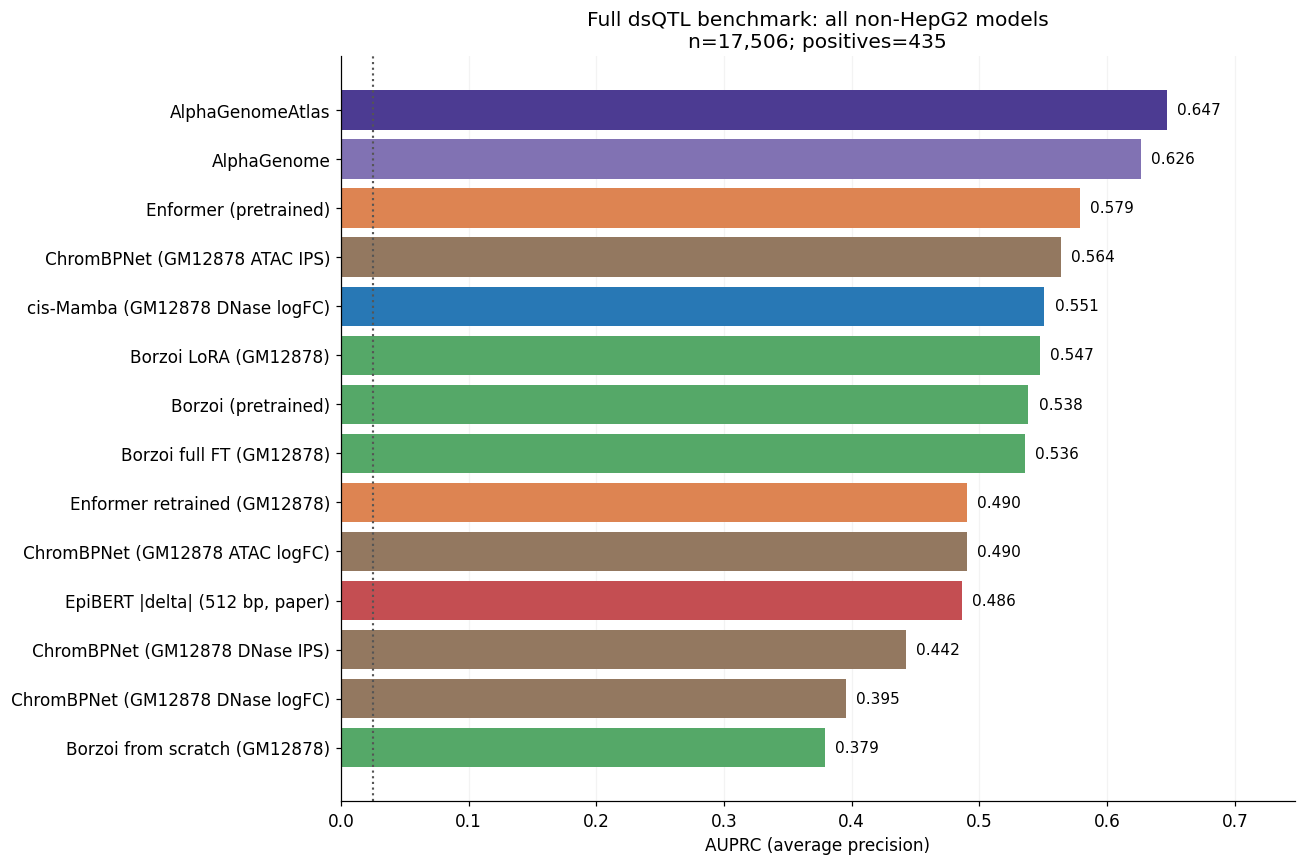

In [3]:
FAMILY_COLORS = {'ours': '#2878B5', 'enformer': '#DD8452', 'borzoi': '#55A868',
                 'alphagenome': '#8172B3', 'chrombpnet': '#937860'}
colors = {name: FAMILY_COLORS[family] for name, family, _ in ARMS}
colors[EPI_PRIMARY] = '#C44E52'
colors[ATLAS_NAME] = '#4C3B92'
for name in epi_scores:
    colors[name] = '#C44E52'

def bars(ax, table, group, order, title):
    vals = table.loc[order, group].to_numpy()
    ax.barh(np.arange(len(order)), vals, color=[colors[n] for n in order])
    ax.set_yticks(np.arange(len(order)), order)
    ax.invert_yaxis()
    ax.axvline(counts.loc[group, 'Chance AP'], color='#555555', ls=':', lw=1.4)
    ax.set_xlim(0, min(1, max(.1, float(vals.max())+.10)))
    for i, value in enumerate(vals):
        ax.text(value+.008, i, f'{value:.3f}', va='center', fontsize=10)
    ax.set_xlabel('AUPRC (average precision)')
    ax.set_title(f'{title}\nn={int(counts.loc[group, "Variants"]):,}; positives={int(counts.loc[group, "Positives"])}')
    ax.grid(axis='x', alpha=.15)
    ax.set_axisbelow(True)

order = results.sort_values('Overall', ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(12, 8))
bars(ax, results, 'Overall', order, 'Full dsQTL benchmark: all non-HepG2 models')
fig.tight_layout()
plt.show()

## Differences by peak specificity

Merged GM12878 DNase peaks are classified by their breadth across the original
track panel. High specificity means breadth ≤68; low specificity means >68.
Variants outside those peaks remain in the overall analysis but do not enter
either specificity panel. Each group has its own positive prevalence.

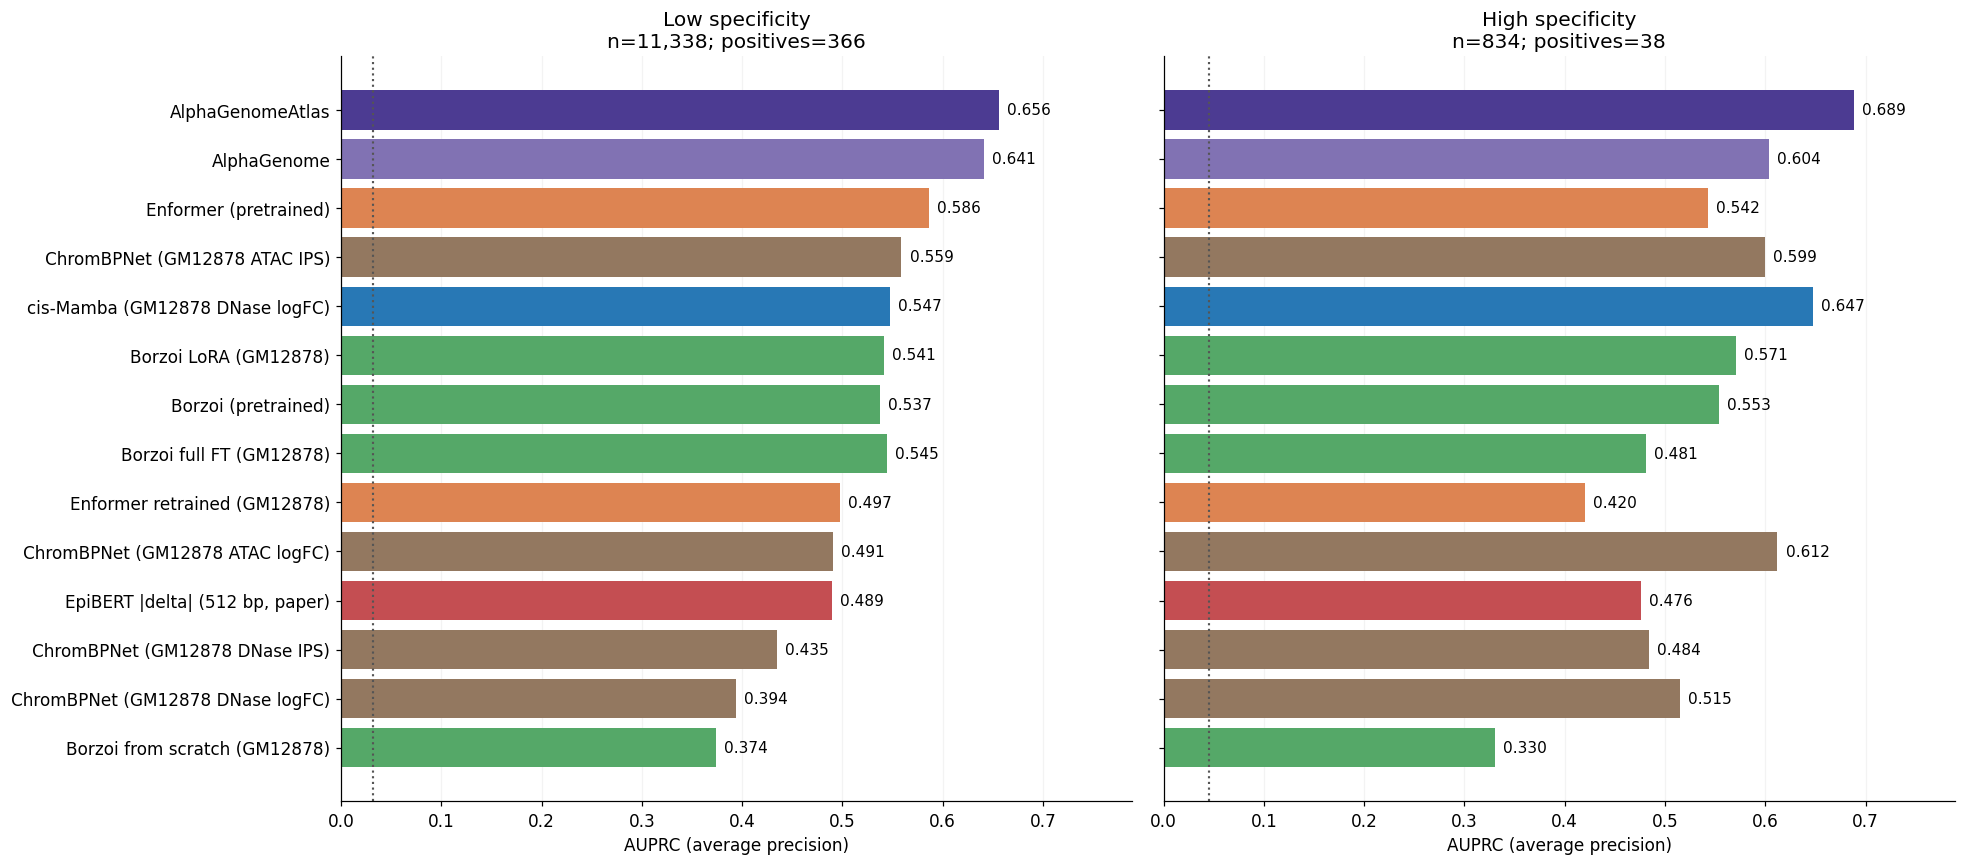

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True)
for ax, group, title in zip(axes, list(masks)[1:], ['Low specificity', 'High specificity']):
    bars(ax, results, group, order, title)
axes[1].tick_params(labelleft=False)
axes[0].set_xlim(0, min(1, results.iloc[:, 1:].to_numpy().max()+.10))
fig.tight_layout()
plt.show()

## Precision–recall curves

Selected principal models use their original scores; the legend includes each
panel's AP. The prevalence line varies by subset. High specificity has relatively
few positives, so apparent differences need uncertainty estimates.

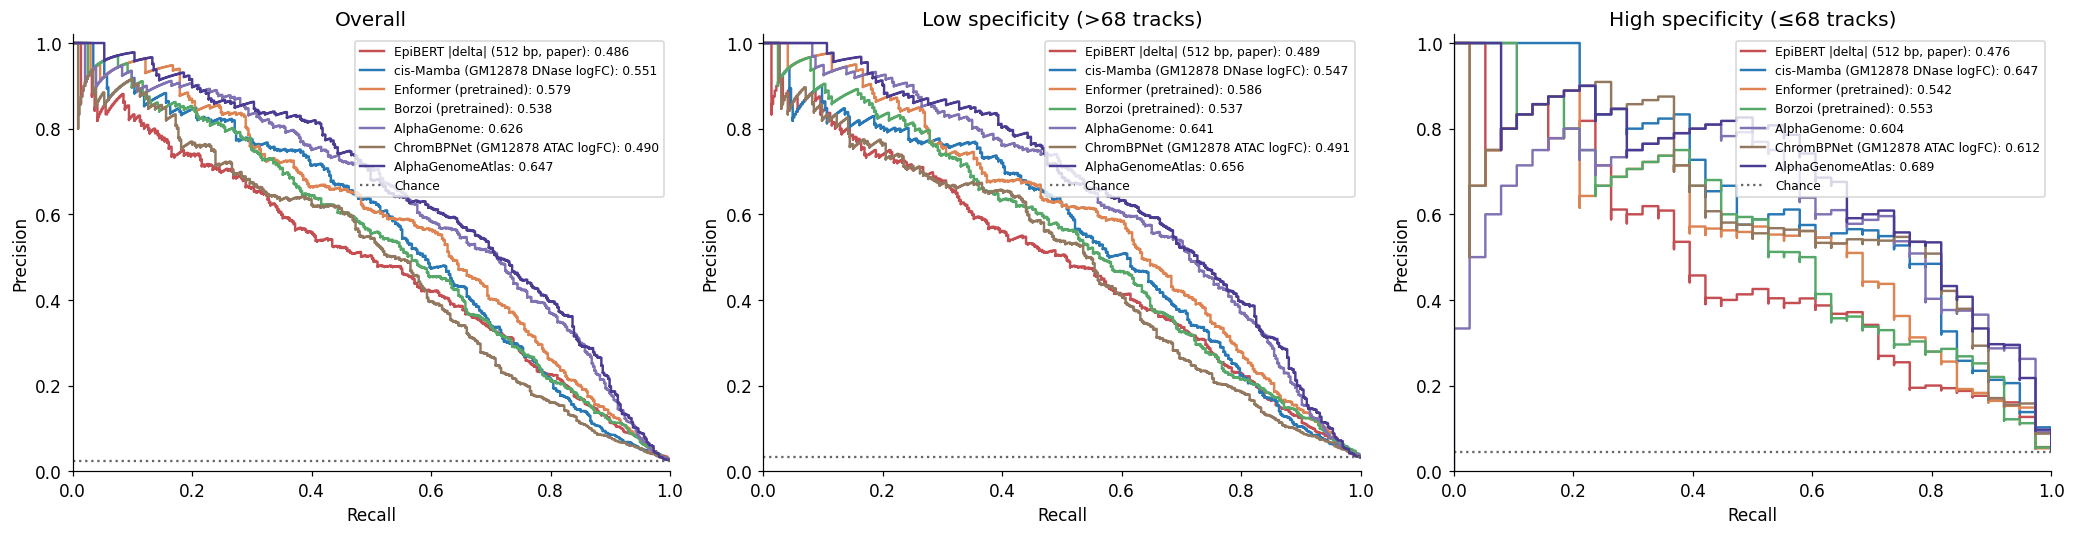

In [5]:
curve_names = [EPI_PRIMARY, ARMS[0][0], ARMS[1][0], ARMS[3][0], ARMS[7][0], ARMS[10][0]]
curve_names.append(ATLAS_NAME)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (group, mask) in zip(axes, masks.items()):
    for name in curve_names:
        precision, recall, _ = precision_recall_curve(y[mask], scores[name][mask])
        ax.step(recall, precision, where='post', color=colors[name], lw=1.6,
                label=f'{name}: {results.loc[name, group]:.3f}')
    ax.axhline(y[mask].mean(), color='#666666', ls=':', label='Chance')
    ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel='Recall', ylabel='Precision', title=group)
    ax.legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()

## EpiBERT scoring sensitivity

The primary paper score stays fixed. LogFC scores normalize the change by predicted
level and can rank variants differently. The 2,048-bp option matches the window
width used by the notebook's Enformer/Borzoi arms, though their predicted assays
and model inputs still differ. The 1,536-bp option covers the entire ATAC mask.

,Overall,Low specificity (>68 tracks),High specificity (≤68 tracks)
"EpiBERT |delta| (512 bp, paper)",0.4862,0.4892,0.4758
EpiBERT logFC (512 bp),0.4269,0.4428,0.4902
EpiBERT logFC (1536 bp),0.4590,0.4702,0.5153
EpiBERT logFC (2048 bp),0.4715,0.4808,0.5202
cis-Mamba (GM12878 DNase logFC),0.5508,0.5473,0.6473
Enformer (pretrained),0.5786,0.5860,0.5424
Borzoi (pretrained),0.5384,0.5373,0.5534
AlphaGenome,0.6263,0.6412,0.6036
AlphaGenomeAtlas,0.6469,0.6560,0.6888


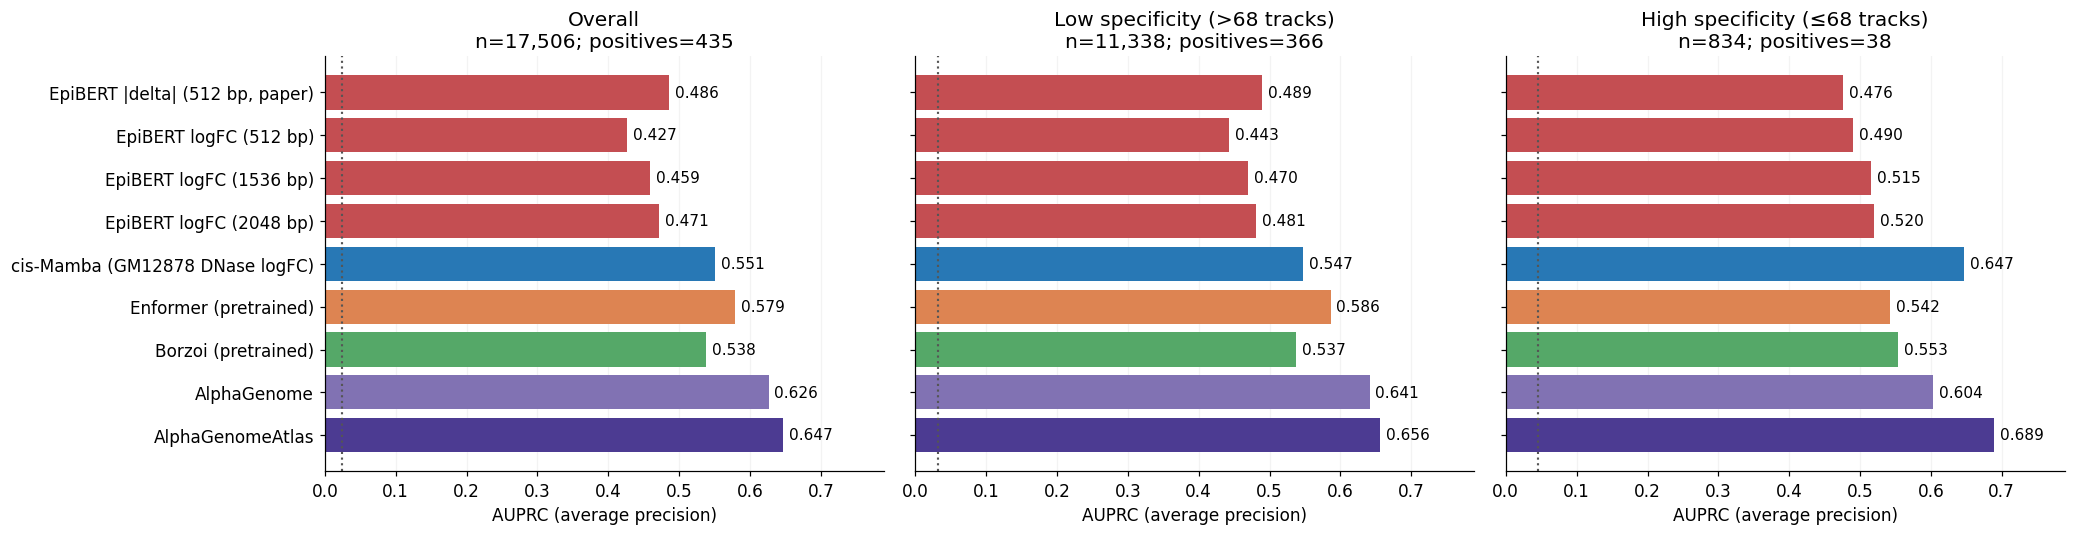

In [6]:
sensitivity_names = [EPI_PRIMARY, 'EpiBERT logFC (512 bp)', 'EpiBERT logFC (1536 bp)',
                     'EpiBERT logFC (2048 bp)', ARMS[0][0], ARMS[1][0], ARMS[3][0], ARMS[7][0]]
sensitivity_names.append(ATLAS_NAME)
sensitivity = ap_table(sensitivity_names)
display(sensitivity.round(4))
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharex=True)
for ax, group in zip(axes, masks):
    bars(ax, sensitivity, group, sensitivity_names, group)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
axes[0].set_xlim(0, min(1, sensitivity.to_numpy().max()+.10))
fig.tight_layout()
plt.show()

## Paired uncertainty: cis-Mamba minus EpiBERT

The bootstrap resamples merged peak clusters, using the same draws for the two
models; variants outside annotated peaks use chromosome/128-bp-bin clusters.
These descriptive percentile intervals use 300 draws. They do not account for
training leakage, choosing among alternative scores, or all possible model comparisons.
A positive AP gap favors cis-Mamba.

In [7]:
rng = np.random.default_rng(42)
N_BOOT = 300
bootstrap_rows = []
for group, mask in masks.items():
    idx = np.flatnonzero(mask)
    cluster = v.iloc[idx].merged_peak_id.fillna('').to_numpy().astype(str)
    fallback = (v.iloc[idx].chrom_hg38 + ':' + v.iloc[idx].bin_index.astype(str)).to_numpy()
    cluster = np.where(cluster == '', fallback, cluster)
    unique, inverse = np.unique(cluster, return_inverse=True)
    members = [np.flatnonzero(inverse == i) for i in range(len(unique))]
    draws = []
    for _ in range(N_BOOT):
        selected = np.concatenate([members[j] for j in rng.integers(0, len(unique), len(unique))])
        rows = idx[selected]
        if np.unique(y[rows]).size != 2:
            continue
        draws.append(average_precision_score(y[rows], scores[ARMS[0][0]][rows]) -
                     average_precision_score(y[rows], scores[EPI_PRIMARY][rows]))
    low, high = np.percentile(draws, [2.5, 97.5])
    bootstrap_rows.append({'Subset': group, 'cis-Mamba minus EpiBERT AP': results.loc[ARMS[0][0], group]-results.loc[EPI_PRIMARY, group],
                           '95% lower': low, '95% upper': high, 'Clusters': len(unique), 'Valid draws': len(draws)})
paired = pd.DataFrame(bootstrap_rows).set_index('Subset')
display(paired.round(4))

,cis-Mamba minus EpiBERT AP,95% lower,95% upper,Clusters,Valid draws
Subset,,,,,
Overall,0.0646,0.0211,0.1118,16447,300
Low specificity (>68 tracks),0.0582,0.0022,0.1148,10357,300
High specificity (≤68 tracks),0.1716,0.0219,0.3067,805,300


The finished dataset contains additional negatives relative to the interim snapshot.
Use these full results for model comparisons. High-specificity performance means
dsQTL detection within these annotated peaks; accurate context specificity needs
comparisons with measured effects under multiple cell types.

## AlphaGenome versus Atlas: matching the score definition

The original arm above uses 1,000 bp without a pseudocount. Below, the saved
AlphaGenome output is restricted to the central 501 bp and scored with the same
+1 pseudocount as Atlas. This isolates the remaining prediction differences from
window and pseudocount differences. The matched scores were computed from all
17,506 saved profiles, without inference, by `dsQTL_ag_501_benchmark.py`.


,Overall,Low specificity (>68 tracks),High specificity (≤68 tracks)
AlphaGenome: matched 501 bp + pseudocount,0.6432,0.6547,0.6281
AlphaGenomeAtlas,0.6469,0.6560,0.6888


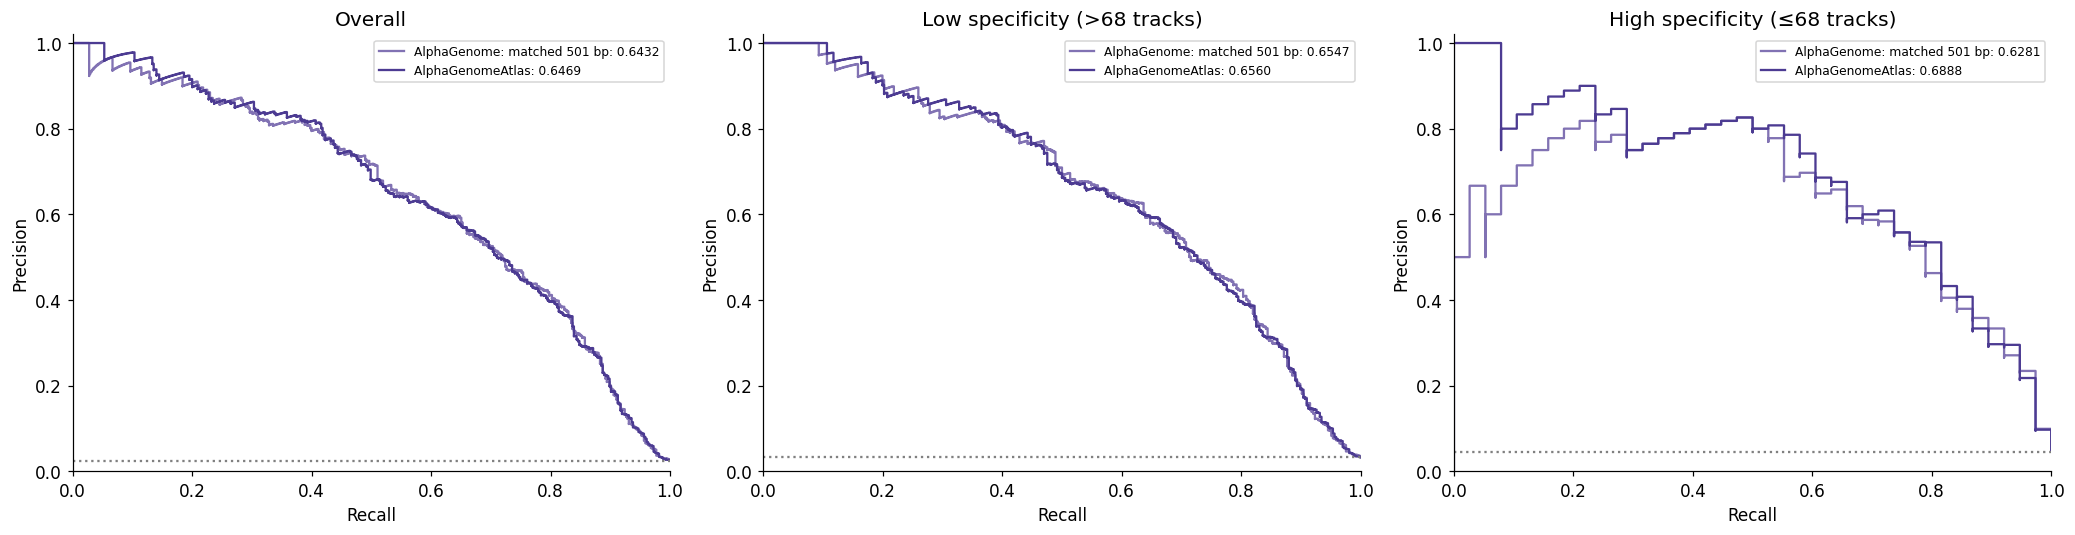

In [8]:
matched = pd.read_csv('/data1/lesliec/sarthak/alphagenome/api/logs/dsqtl_ag_501_benchmark/per_variant_scores.tsv', sep='\t')
np.testing.assert_array_equal(matched.row_id, np.arange(len(q)))
np.testing.assert_array_equal(matched.rsid, q.SNPname2)
np.testing.assert_array_equal(matched.label, y)
np.testing.assert_allclose(matched.atlas_native, atlas_signed, atol=1e-14, rtol=1e-12)
matched_old = np.abs(matched.original_501_atlas_formula.to_numpy())
matched_results = pd.DataFrame({
    group: [average_precision_score(y[mask], matched_old[mask]), results.loc[ATLAS_NAME, group]]
    for group, mask in masks.items()
}, index=['AlphaGenome: matched 501 bp + pseudocount', ATLAS_NAME])
display(matched_results.round(4))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, (group, mask) in zip(axes, masks.items()):
    for name, values, color in [('AlphaGenome: matched 501 bp', matched_old, colors['AlphaGenome']),
                                 (ATLAS_NAME, scores[ATLAS_NAME], colors[ATLAS_NAME])]:
        precision, recall, _ = precision_recall_curve(y[mask], values[mask])
        ap = average_precision_score(y[mask], values[mask])
        ax.step(recall, precision, where='post', color=color, label=f'{name}: {ap:.4f}')
    ax.axhline(y[mask].mean(), color='gray', ls=':')
    ax.set(xlim=(0,1), ylim=(0,1.02), xlabel='Recall', ylabel='Precision', title=group)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


The cell-type-specific subset contains 834 variants and 38 positives. A high
correlation across score magnitudes does not ensure identical ordering at the top
of the list. For example, the negative rs4295943 ranks first in the matched saved
AlphaGenome scores and 14th in Atlas. The top 20 contain 16 positives under each
method, and the top 50 contain 28 under each; their ordering differs.

A separate paired bootstrap of the original merged-peak clusters (2,000 draws,
seed 42) gives a 95% percentile interval of approximately −0.0036 to +0.1160 for
the matched-501-bp Atlas-minus-AlphaGenome AP gap. This small subset does not
establish a robust general improvement from the observed +0.0607 gap alone.
The source of the remaining per-variant prediction differences has not been
isolated by these saved-output comparisons.


## Signed Pearson correlation with measured dsQTL beta

Evaluate **all 14 primary model/scorer arms**, including `AlphaGenomeAtlas`, on
all available measured effects: **435 positives + 35 negatives = 470 variants**.
The other 17,036 negatives have no beta and are excluded, never assigned zero.
Combined, positive-only and negative-only results use fixed shared rows.

The [original preprocessing](https://github.com/kundajelab/chrombpnet-figures/blob/main/src/figures_factory/Fig6/preprocessing/format_dsqtls.ipynb)
aligns beta to **allele1 relative to allele2**. Saved model arrays use genomic
REF then ALT, so signed ALT-minus-REF effects are retained when allele1=ALT
(322 rows) and negated when allele1=REF (148 rows). Directions are established
from allele identities and the prediction scripts, not optimized against beta.

Scoring windows match the preceding classification benchmark. For logFC arms,
remove the absolute value and harmonize the sign. EpiBERT's primary score becomes
a **signed 512-bp count difference**; its three logFC windows are also shown as
sensitivity results. ChromBPNet logFC is already beta-aligned. IPS is unsigned,
so **signed IPS = abs(IPS) × sign(logFC)** from the same track; it remains a
prioritization score rather than a direct log-fold change. All signed magnitudes
are checked against the original classification scores.


In [9]:
# Signed effect-size benchmark: executed after benchmark 10's existing cells.
from scipy.stats import pearsonr

SIGNED_OUT = Path('/data1/lesliec/sarthak/alphagenome/api/logs/dsqtl_all_models_signed_beta')
SIGNED_OUT.mkdir(parents=True, exist_ok=True)
BETA_SOURCE = Path('/data1/lesliec/sarthak/data/chrombpnet/dsqtls.yoruba.lcls.benchmarking.all.tsv')
beta_data = pd.read_csv(BETA_SOURCE, sep='\t')
beta_data['_key'] = beta_data['var.chr'] + ':' + beta_data['var.pos_hg19'].astype(str)
needed_beta = ['var.rsid', 'var.allele1', 'var.allele2', 'obs.label', 'obs.estimate']
needed_beta += [f'pred.chrombpnet.{track}.varscore.{metric}'
                for track in ['encsr000emt', 'encsr637xsc'] for metric in ['logfc','ips']]
beta_dups = beta_data[beta_data._key.duplicated(keep=False)]
assert beta_dups.groupby('_key')[needed_beta].nunique(dropna=False).le(1).all().all()
beta_data = beta_data.drop_duplicates('_key').set_index('_key').reindex(
    q.chrom_hg19 + ':' + q.pos_hg19.astype(str)).reset_index(drop=True)
for source_col, input_col in [('var.rsid','SNPname2'), ('var.allele1','allele1'),
                              ('var.allele2','allele2'), ('obs.label','label')]:
    np.testing.assert_array_equal(beta_data[source_col], q[input_col])
BETA = pd.to_numeric(beta_data['obs.estimate'], errors='raise').to_numpy()
BETA_MASK = np.isfinite(BETA) & common
BETA_ROWS = np.flatnonzero(BETA_MASK)
assert len(BETA_ROWS) == 470
assert int(y[BETA_MASK].sum()) == 435
# Original preprocessing defines beta in allele1-minus-allele2 direction.
# Its Enformer harmonization retains ALT-REF when ALT=allele1, negates otherwise.
a1_is_alt = (beta_data['var.allele1'] == atlas_saved.alternate) & (beta_data['var.allele2'] == atlas_saved.reference)
a1_is_ref = (beta_data['var.allele1'] == atlas_saved.reference) & (beta_data['var.allele2'] == atlas_saved.alternate)
assert (a1_is_alt | a1_is_ref)[BETA_MASK].all()
BETA_SIGN = np.where(a1_is_alt, 1., np.where(a1_is_ref, -1., np.nan))[BETA_ROWS]
assert (BETA_SIGN == 1).sum() == 322 and (BETA_SIGN == -1).sum() == 148
SIGNED = {}
SIGNED_DEFINITIONS = {}

def add_signed(name, values, definition, expected_abs=None):
    values = np.asarray(values, dtype=np.float64)
    assert values.shape == (470,) and np.isfinite(values).all(), name
    if expected_abs is not None:
        np.testing.assert_allclose(np.abs(values), expected_abs, rtol=1e-9, atol=1e-12,
                                   err_msg=f'{name}: signed magnitudes differ from existing benchmark')
    SIGNED[name] = values
    SIGNED_DEFINITIONS[name] = definition

for ai, (name, family, filename) in enumerate(ARMS):
    if isinstance(filename, tuple):
        track, metric = filename
        value = beta_data[f'pred.chrombpnet.{track}.varscore.{metric}'].to_numpy()[BETA_ROWS]
        if metric == 'ips':
            # IPS is unsigned; attach the direction of the same track's harmonized logFC.
            direction = np.sign(beta_data[f'pred.chrombpnet.{track}.varscore.logfc'].to_numpy()[BETA_ROWS])
            assert not np.any((direction == 0) & (value != 0))
            value = np.abs(value) * direction
            definition = 'Signed IPS = abs(IPS) * sign(beta-aligned logFC); direction added to unsigned prioritization score'
        else:
            definition = 'Native ChromBPNet logFC, already aligned to allele1-minus-allele2 by source preprocessing'
        add_signed(name, value, definition, base_scores[BETA_ROWS,ai])
    elif name == 'AlphaGenome':
        # Sums were computed directly from every saved 1000-bp REF/ALT profile.
        ag_rows = pd.read_csv('/data1/lesliec/sarthak/alphagenome/api/logs/dsqtl_ag_501_benchmark/per_variant_scores.tsv', sep='\t')
        np.testing.assert_array_equal(ag_rows.row_id, np.arange(len(q)))
        np.testing.assert_array_equal(ag_rows.rsid, q.SNPname2)
        add_signed(name, ag_rows.original_1000_no_pc.to_numpy()[BETA_ROWS] * BETA_SIGN,
                   '1000-bp saved profile: log2(ALT/REF), no pseudocount, aligned to beta allele1', base_scores[BETA_ROWS,ai])
    else:
        array = np.load(DSQ / filename, mmap_mode='r')
        assert array.ndim == 3 and array.shape[0] == len(q) and array.shape[2] == 2
        if family == 'borzoi':
            assert array.shape[1] == 6144
            lo, hi = 3040, 3104
        elif family == 'enformer':
            assert array.shape[1] == 896
            lo, hi = 440, 456
        else:
            lo, hi = 0, array.shape[1]
        pair = np.asarray(array[BETA_ROWS,lo:hi,:],dtype=np.float64)
        assert np.isfinite(pair).all() and (pair >= 0).all()
        means = pair.mean(axis=1)
        assert (means > 0).all()
        value = np.log2(means[:,1]/means[:,0]) * BETA_SIGN
        add_signed(name, value, f'Saved REF/ALT channels, bins [{lo}:{hi}], log2(ALT/REF) without pseudocount; aligned to beta allele1', base_scores[BETA_ROWS,ai])
        del pair, array

for window, (lo, hi) in WINDOWS.items():
    pair = np.asarray(epi[BETA_ROWS,lo:hi,:],dtype=np.float64).sum(axis=1)
    assert (pair > 0).all()
    name = f'EpiBERT logFC ({window})'
    add_signed(name, np.log2(pair[:,1]/pair[:,0]) * BETA_SIGN,
               f'EpiBERT log2(ALT/REF), {window}, aligned to beta allele1', epi_scores[name][BETA_ROWS])
    if window == '512 bp':
        add_signed(EPI_PRIMARY, (pair[:,1]-pair[:,0]) * BETA_SIGN,
                   'Signed ALT-REF sum over four central 128-bp bins (512 bp), aligned to beta allele1; absolute value removed from primary classification score', epi_scores[EPI_PRIMARY][BETA_ROWS])
add_signed(ATLAS_NAME, atlas_signed[BETA_ROWS] * BETA_SIGN,
           'Native Atlas 501-bp DNase log2((ALT sum+1)/(REF sum+1)), aligned to beta allele1', scores[ATLAS_NAME][BETA_ROWS])
SIGNED_PRIMARY_NAMES = list(names)
assert len(SIGNED_PRIMARY_NAMES) == 14 and set(SIGNED_PRIMARY_NAMES) <= SIGNED.keys()
# Use distinct display labels wherever the magnitude-only score gained a sign.
SIGNED_LABELS = {name: name.replace('ATAC IPS)', 'ATAC signed IPS)').replace('DNase IPS)', 'DNase signed IPS)') for name in SIGNED}
SIGNED_LABELS[EPI_PRIMARY] = 'EpiBERT signed delta (512 bp, paper)'
SIGNED_ROWS = []
for population, pm in [('Combined',np.ones(470,dtype=bool)), ('Positives',y[BETA_ROWS]==1), ('Negatives',y[BETA_ROWS]==0)]:
    for stratum, sm in [('Overall',np.ones(470,dtype=bool)),
                        ('Generic',specificity[BETA_ROWS]=='low_specificity'),
                        ('Cell-type-specific',specificity[BETA_ROWS]=='high_specificity')]:
        mask = pm & sm
        for name, value in SIGNED.items():
            if mask.sum() >= 3 and np.ptp(BETA[BETA_ROWS][mask]) > 0 and np.ptp(value[mask]) > 0:
                r, p = pearsonr(BETA[BETA_ROWS][mask],value[mask])
            else:
                r, p = np.nan, np.nan
            SIGNED_ROWS.append(dict(population=population,stratum=stratum,model=name,
                display_name=SIGNED_LABELS[name],n=int(mask.sum()),positives=int(y[BETA_ROWS][mask].sum()),
                negatives=int(mask.sum()-y[BETA_ROWS][mask].sum()),pearson_r=r,pvalue=p,
                definition=SIGNED_DEFINITIONS[name]))
SIGNED_RESULTS = pd.DataFrame(SIGNED_ROWS)
SIGNED_RESULTS.to_csv(SIGNED_OUT / 'correlations.tsv',sep='\t',index=False)
# Independent check against previously computed AlphaGenome-only results.
previous = pd.read_csv('/data1/lesliec/sarthak/alphagenome/api/logs/dsqtl_signed_beta_correlation/correlations.tsv',sep='\t')
for population, prev_pop in [('Combined','Positives + negatives'),('Positives','Positives only'),('Negatives','Negatives only')]:
    for name, prev_name in [('AlphaGenome','AlphaGenome (original 1000 bp, no pseudocount)'),(ATLAS_NAME,ATLAS_NAME)]:
        got = SIGNED_RESULTS.query('population == @population and stratum == "Overall" and model == @name').pearson_r.iloc[0]
        want = previous.query('population == @prev_pop and stratum == "Overall" and model == @prev_name').pearson_r.iloc[0]
        np.testing.assert_allclose(got,want,rtol=1e-12,atol=1e-14)
SIGNED_MAIN = SIGNED_RESULTS[SIGNED_RESULTS.stratum.eq('Overall')].pivot(index='model',columns='population',values='pearson_r')
SIGNED_MAIN = SIGNED_MAIN.loc[SIGNED_PRIMARY_NAMES,['Combined','Positives','Negatives']].sort_values('Combined',ascending=False)
print('Signed Pearson correlation: combined n=470; positives n=435; negatives n=35')
display(SIGNED_MAIN.rename(index=SIGNED_LABELS).round(4))
SIGNED_VARIANTS = pd.DataFrame(dict(row_id=BETA_ROWS,rsid=q.SNPname2.iloc[BETA_ROWS].to_numpy(),
    label=y[BETA_ROWS],specificity=specificity[BETA_ROWS],beta=BETA[BETA_ROWS],
    effect_allele=beta_data['var.allele1'].iloc[BETA_ROWS].to_numpy(),
    other_allele=beta_data['var.allele2'].iloc[BETA_ROWS].to_numpy(),
    model_ref=atlas_saved.reference.iloc[BETA_ROWS].to_numpy(),model_alt=atlas_saved.alternate.iloc[BETA_ROWS].to_numpy(),
    alt_ref_to_beta_sign=BETA_SIGN,**SIGNED))
SIGNED_VARIANTS.to_csv(SIGNED_OUT / 'aligned_variants.tsv',sep='\t',index=False)
print('Validated allele directions, score magnitudes against all original arms, and prior AG correlations.')


Signed Pearson correlation: combined n=470; positives n=435; negatives n=35


population,Combined,Positives,Negatives
model,,,
AlphaGenomeAtlas,0.7923,0.8057,0.3564
AlphaGenome,0.7770,0.7900,0.3549
ChromBPNet (GM12878 ATAC logFC),0.7420,0.7527,0.3863
ChromBPNet (GM12878 DNase logFC),0.7195,0.7314,0.3154
Enformer (pretrained),0.7031,0.7169,0.2619
Borzoi full FT (GM12878),0.6990,0.7138,0.3139
Borzoi (pretrained),0.6979,0.7100,0.2942
cis-Mamba (GM12878 DNase logFC),0.6928,0.7031,0.3667
Borzoi LoRA (GM12878),0.6895,0.7007,0.3160


Validated allele directions, score magnitudes against all original arms, and prior AG correlations.


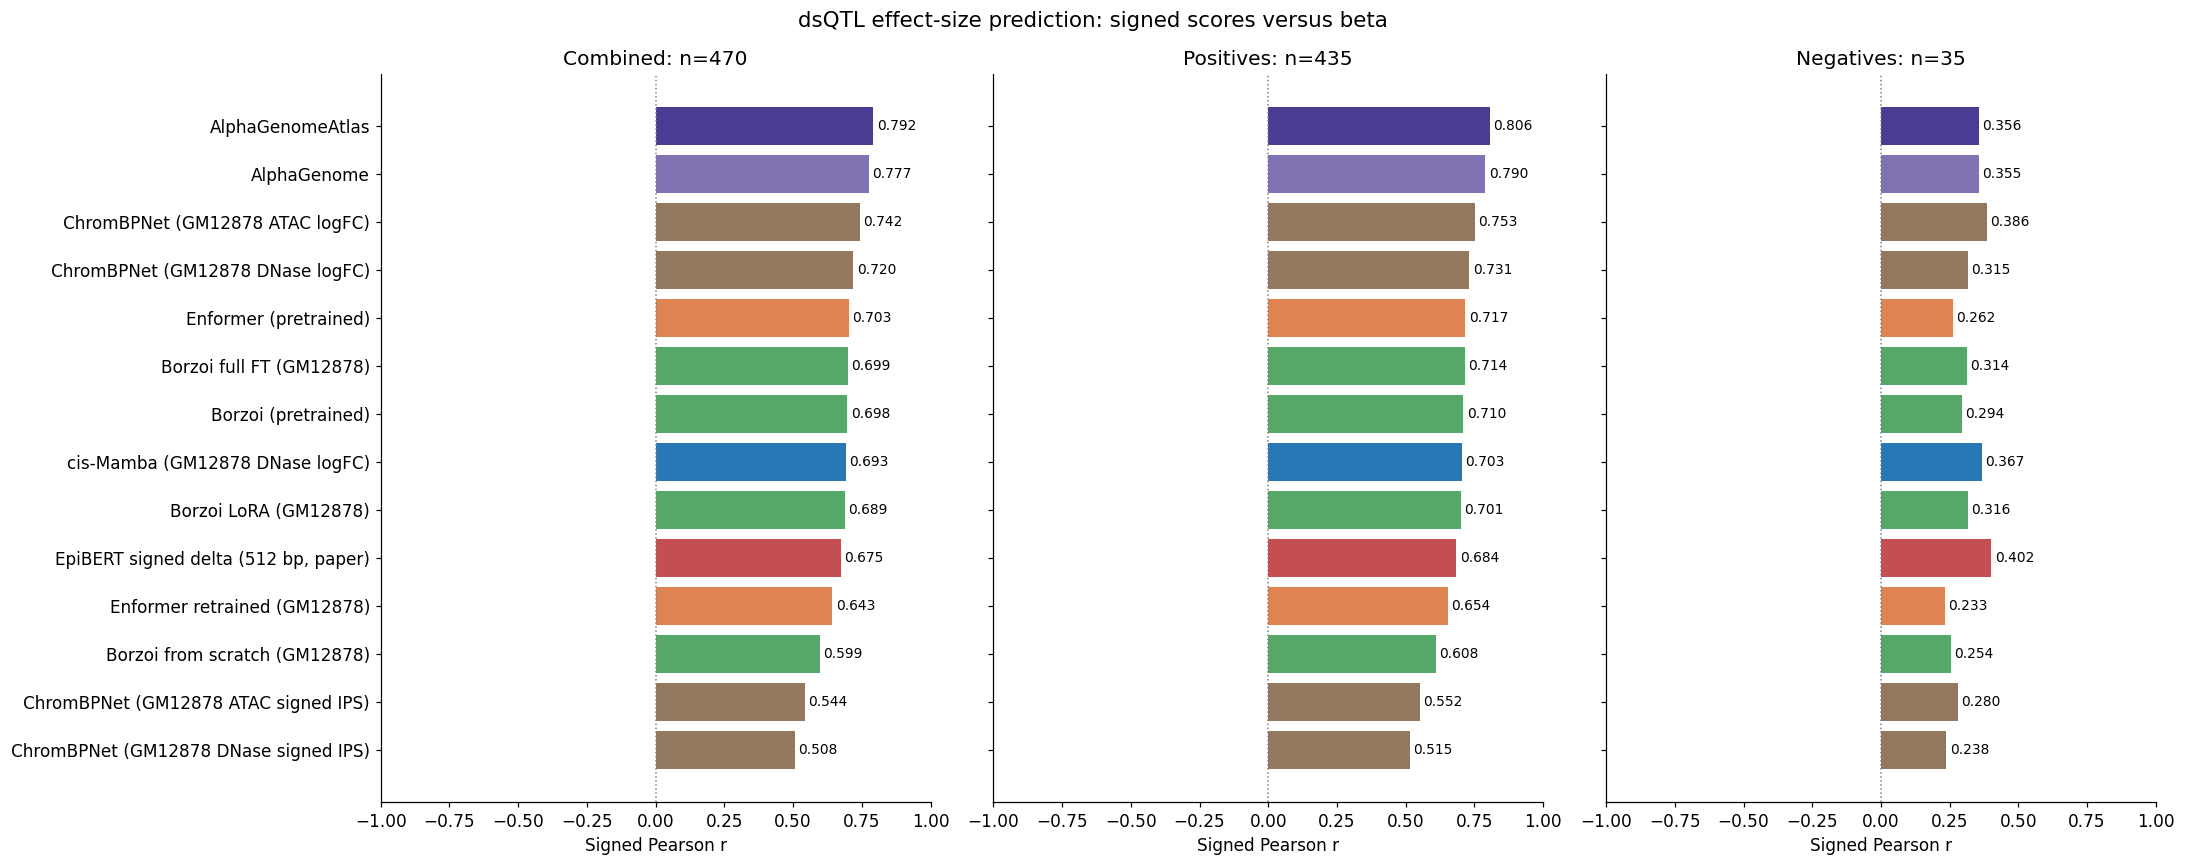

In [10]:
# All primary arms, same ordering in combined/positive/negative panels.
fig, axes = plt.subplots(1, 3, figsize=(20, 8), sharey=True, sharex=True)
signed_order = SIGNED_MAIN.index.tolist()
for ax, population, n in zip(axes,['Combined','Positives','Negatives'],[470,435,35]):
    vals = SIGNED_MAIN.loc[signed_order,population].to_numpy()
    ax.barh(np.arange(len(vals)),vals,color=[colors[name] for name in signed_order])
    ax.set_yticks(np.arange(len(vals)),[SIGNED_LABELS[name] for name in signed_order])
    ax.axvline(0,color='gray',ls=':',lw=1)
    for i,value in enumerate(vals):
        ax.text(value + (.012 if value >= 0 else -.012),i,f'{value:.3f}',
                va='center',ha='left' if value >= 0 else 'right',fontsize=9)
    ax.set(xlim=(-1,1),xlabel='Signed Pearson r',title=f'{population}: n={n}')
axes[0].invert_yaxis()
fig.suptitle('dsQTL effect-size prediction: signed scores versus beta',fontsize=14)
fig.tight_layout()
fig.savefig(SIGNED_OUT/'signed_pearson_all_models.png',dpi=160,bbox_inches='tight')
plt.show()


In [11]:
# The same generic / cell-type-specific peak strata, with measured-beta counts.
for population in ['Combined','Positives','Negatives']:
    subset = SIGNED_RESULTS[(SIGNED_RESULTS.population==population) & SIGNED_RESULTS.model.isin(SIGNED_PRIMARY_NAMES)]
    counts_signed = subset.drop_duplicates('stratum').set_index('stratum')[['n','positives','negatives']]
    strata = subset.pivot(index='model',columns='stratum',values='pearson_r').reindex(signed_order)
    print(f'\n{population}: available beta counts by stratum')
    display(counts_signed)
    display(strata[['Overall','Generic','Cell-type-specific']].rename(index=SIGNED_LABELS).round(4))
print('\nEpiBERT signed-delta versus logFC sensitivity (same measured-beta rows)')
epi_signed_names = [EPI_PRIMARY] + [f'EpiBERT logFC ({w})' for w in WINDOWS]
epi_signed_table = SIGNED_RESULTS[SIGNED_RESULTS.stratum.eq('Overall')].pivot(index='model',columns='population',values='pearson_r')
display(epi_signed_table.loc[epi_signed_names,['Combined','Positives','Negatives']].rename(index=SIGNED_LABELS).round(4))
# Export full definitions and source identities alongside results.
sign_sources = [
 '/data1/lesliec/sarthak/caduceus/evals/dsqtl_onemodel.py',
 '/data1/lesliec/sarthak/enformer-pytorch/dsqtl_benchmark.py',
 '/data1/lesliec/sarthak/borzoi/dsQTL_benchmark.py',
 '/data1/lesliec/sarthak/EpiBERT/dsQTL_benchmark.py',
 '/data1/lesliec/sarthak/alphagenome/api/dsQTL.py',
]
signed_provenance = dict(metric='scipy.stats.pearsonr, signed predictions versus observed beta',
    n_beta=470,positives=435,negatives=35,negatives_missing_beta=17036,
    beta_direction='allele1 relative to allele2',kept_alt_minus_ref=322,flipped_alt_minus_ref=148,
    score_definitions=SIGNED_DEFINITIONS,api_requests=0,
    beta_source=str(BETA_SOURCE),beta_source_sha256=hashlib.sha256(BETA_SOURCE.read_bytes()).hexdigest(),
    prediction_sources=[dict(path=p,sha256=hashlib.sha256(Path(p).read_bytes()).hexdigest()) for p in sign_sources])
(SIGNED_OUT/'provenance.json').write_text(json.dumps(signed_provenance,indent=2))
print('ALL-MODEL SIGNED BETA CORRELATION COMPLETE')



Combined: available beta counts by stratum


,n,positives,negatives
stratum,,,
Overall,470,435,35
Generic,397,366,31
Cell-type-specific,41,38,3


stratum,Overall,Generic,Cell-type-specific
model,,,
AlphaGenomeAtlas,0.7923,0.7847,0.8777
AlphaGenome,0.7770,0.7703,0.8758
ChromBPNet (GM12878 ATAC logFC),0.7420,0.7364,0.8350
ChromBPNet (GM12878 DNase logFC),0.7195,0.7142,0.7946
Enformer (pretrained),0.7031,0.6921,0.7837
Borzoi full FT (GM12878),0.6990,0.6877,0.8128
Borzoi (pretrained),0.6979,0.6840,0.8092
cis-Mamba (GM12878 DNase logFC),0.6928,0.6819,0.8074
Borzoi LoRA (GM12878),0.6895,0.6731,0.8063



Positives: available beta counts by stratum


,n,positives,negatives
stratum,,,
Overall,435,435,0
Generic,366,366,0
Cell-type-specific,38,38,0


...

,n,positives,negatives
stratum,,,
Overall,35,0,35
Generic,31,0,31
Cell-type-specific,3,0,3


stratum,Overall,Generic,Cell-type-specific
model,,,
AlphaGenomeAtlas,0.3564,0.2739,0.9881
AlphaGenome,0.3549,0.2756,0.9900
ChromBPNet (GM12878 ATAC logFC),0.3863,0.3206,0.9956
ChromBPNet (GM12878 DNase logFC),0.3154,0.2163,0.9999
Enformer (pretrained),0.2619,0.1582,0.9819
Borzoi full FT (GM12878),0.3139,0.2326,0.9637
Borzoi (pretrained),0.2942,0.1593,0.9436
cis-Mamba (GM12878 DNase logFC),0.3667,0.2634,0.9967
Borzoi LoRA (GM12878),0.3160,0.2034,0.9645



EpiBERT signed-delta versus logFC sensitivity (same measured-beta rows)


population,Combined,Positives,Negatives
model,,,
"EpiBERT signed delta (512 bp, paper)",0.6753,0.6842,0.4018
EpiBERT logFC (512 bp),0.7147,0.7246,0.4279
EpiBERT logFC (1536 bp),0.7167,0.7269,0.3975
EpiBERT logFC (2048 bp),0.7189,0.7291,0.3951


ALL-MODEL SIGNED BETA CORRELATION COMPLETE


The combined result is dominated by positive dsQTLs because most negative
variants lack measured beta. The negative-only group has just 35 variants;
its generic and cell-type-specific subdivisions are smaller still. Correlations
with fewer than three observations or a constant score are reported as missing.
These subsets should not be interpreted as representing all negative controls.
